# Práctica dirigida N.º 2
## Backpropagation manual y CNN para MNIST

**Universidad Nacional de Ingeniería · Unidad de Posgrado FIIS**  
Solución actualizada con `Practica_2_Backprop_CNN.pdf`, `ExampleofNeuralNetworks.ipynb` y `NeuralNetwork_MNIST.ipynb`.

**Para Google Colab:** sube este archivo y ejecuta las celdas en orden. Una GPU es opcional y acelera el entrenamiento. MNIST se descarga automáticamente si no está disponible.

Se desarrolla el cálculo manual completo y se implementa la CNN exacta del PDF durante **3 épocas**. Se reutilizan la clase MLP y las funciones de entrenamiento y evaluación del adjunto que contiene validación. El MLP se entrena **5 épocas**, como en ese adjunto, y también se evalúa su estado de la época 3 para comparar con la CNN con igual número de épocas.

**La comparación principal usa 42 000 ejemplos de train, 18 000 de validación y 10 000 de test.** El resultado histórico del adjunto, **97.61 %**, se conserva y se distingue de las métricas calculadas en esta nueva ejecución.

**Ejecución incluida:** las 16 celdas de código se ejecutaron correctamente en CPU con semilla 42. Las salidas y gráficas están guardadas; al repetir el experimento en otro entorno pueden variar las métricas y los tiempos.

## Qué se reutiliza de los adjuntos

| Aspecto | `ExampleofNeuralNetworks.ipynb` | `NeuralNetwork_MNIST.ipynb` |
|---|---|---|
| Arquitectura MLP | 784 → 256 → 128 → 10, ReLU | La misma |
| Transformaciones | `ToTensor` + `Normalize(0.1307, 0.3081)` | Las mismas |
| Train / validación / test | 42 000 / 18 000 / 10 000 | 60 000 / sin validación / 10 000 |
| Batch de entrenamiento | 64 | 64 |
| Batch de validación / test | 64 / 64 | No aplica / 1 000 |
| Optimizador y pérdida | Adam, lr = 0.001, CrossEntropyLoss | Los mismos |
| Épocas | 5 | 5 |
| Test accuracy guardado | **0.9761 = 97.61 %** | No hay salida de accuracy guardada |

Se usa **`ExampleofNeuralNetworks.ipynb` como base de datos y entrenamiento**, porque el PDF exige train/val/test. El segundo adjunto confirma la arquitectura del MLP, pero usa todo el conjunto de entrenamiento y no separa validación.

**Reproducibilidad:** el primer adjunto ejecuta `random_split` sin fijar semilla y no guarda sus índices. Por ello no se pueden reconstruir los ejemplos exactos usados en su ejecución histórica. Aquí se conserva su proporción **70/30** y se genera **una sola partición con semilla 42**, compartida por todos los modelos. Tampoco se supone que el 97.61 % histórico deba repetirse exactamente.

## 1. Backpropagation manual

Se calcula la derivada de **la salida (f)**, porque esta parte no define una función de pérdida ni una etiqueta objetivo.

$$f(w,x)=\frac{1}{1+e^{-(w_0x_0+w_1x_1+w_2)}}.$$

| Variable | Valor |
|---|---:|
| $w_0$ | 1 |
| $x_0$ | -2 |
| $w_1$ | -2 |
| $x_1$ | -1 |
| $w_2$ (sesgo) | -1 |

### 1.1. Forward pass: los ocho nodos

Se conserva el orden del circuito del enunciado. Los decimales de las tablas están redondeados; el código conserva la precisión completa.

| Orden | Nodo | Operación y sustitución | Salida |
|---:|---|---|---:|
| 1 | $a=w_0x_0$ | $1(-2)$ | -2 |
| 2 | $b=w_1x_1$ | $(-2)(-1)$ | 2 |
| 3 | $c=a+b$ | $-2+2$ | 0 |
| 4 | $z=c+w_2$ | $0-1$ | -1 |
| 5 | $d=-z$ | $-(-1)$ | 1 |
| 6 | $e=\exp(d)$ | $\exp(1)$ | 2.71828183 |
| 7 | $h=e+1$ | $2.71828183+1$ | 3.71828183 |
| 8 | $f=1/h$ | $1/3.71828183$ | **0.26894142** |

Aquí $e$ es el nombre de un nodo; en esta evaluación su valor coincide con el número de Euler porque $d=1$.

$$\boxed{f=\sigma(-1)=\frac{1}{1+e^1}=0.268941421370}$$

Se cumple $0<f<1$.

### 1.2. Backward pass: de derecha a izquierda

Para un nodo $y=g(u)$:

$$\frac{\partial f}{\partial u}
=\underbrace{\frac{\partial y}{\partial u}}_{\text{gradiente local}}
\underbrace{\frac{\partial f}{\partial y}}_{\text{gradiente recibido (upstream)}}.$$

Se inicia con $\partial f/\partial f=1$. En las sumas se transmite el mismo gradiente a cada entrada; en los productos se multiplica por la otra entrada.

| Nodo procesado | Entrada a derivar | Fórmula local | Valor local | Upstream | Gradiente hacia la entrada |
|---|---|---|---:|---:|---:|
| $f=1/h$ | $h$ | $-1/h^2$ | -0.07232949 | 1.00000000 | -0.07232949 |
| $h=e+1$ | $e$ | $1$ | 1.00000000 | -0.07232949 | -0.07232949 |
| $e=\exp(d)$ | $d$ | $\exp(d)$ | 2.71828183 | -0.07232949 | -0.19661193 |
| $d=-z$ | $z$ | $-1$ | -1.00000000 | -0.19661193 | 0.19661193 |
| $z=c+w_2$ | $c$ | $1$ | 1.00000000 | 0.19661193 | 0.19661193 |
| $z=c+w_2$ | $w_2$ | $1$ | 1.00000000 | 0.19661193 | 0.19661193 |
| $c=a+b$ | $a$ | $1$ | 1.00000000 | 0.19661193 | 0.19661193 |
| $c=a+b$ | $b$ | $1$ | 1.00000000 | 0.19661193 | 0.19661193 |
| $a=w_0x_0$ | $w_0$ | $x_0$ | -2.00000000 | 0.19661193 | -0.39322387 |
| $a=w_0x_0$ | $x_0$ | $w_0$ | 1.00000000 | 0.19661193 | 0.19661193 |
| $b=w_1x_1$ | $w_1$ | $x_1$ | -1.00000000 | 0.19661193 | -0.19661193 |
| $b=w_1x_1$ | $x_1$ | $w_1$ | -2.00000000 | 0.19661193 | -0.39322387 |

Por ejemplo:

$$\frac{\partial f}{\partial d}
=\left(-\frac{1}{(1+e^1)^2}\right)\cdot e^1
=-0.196611933241,$$

$$\frac{\partial f}{\partial z}
=(-0.196611933241)(-1)=0.196611933241.$$

Los signos negativos consecutivos del inverso y de la multiplicación por $-1$ hacen positiva la derivada respecto a $z$.

### 1.3. Los cinco gradientes finales

Como comprobación algebraica, $\sigma'(z)=\sigma(z)(1-\sigma(z))=0.196611933241$.

| Gradiente | Sustitución | Resultado |
|---|---|---:|
| $\partial f/\partial w_0$ | $\sigma'(z)x_0$ | **-0.393223866483** |
| $\partial f/\partial x_0$ | $\sigma'(z)w_0$ | **0.196611933241** |
| $\partial f/\partial w_1$ | $\sigma'(z)x_1$ | **-0.196611933241** |
| $\partial f/\partial x_1$ | $\sigma'(z)w_1$ | **-0.393223866483** |
| $\partial f/\partial w_2$ | $\sigma'(z)$ | **0.196611933241** |

### 1.4. Verificación en Python, sin autodiferenciación

La celda siguiente reproduce literalmente la regla de la cadena del circuito.

In [1]:
import math

w0, x0, w1, x1, w2 = 1.0, -2.0, -2.0, -1.0, -1.0

# Forward, en el orden solicitado.
a = w0 * x0
b = w1 * x1
c = a + b
z = c + w2
d = -z
e = math.exp(d)
h = e + 1.0
f_manual = 1.0 / h

forward_manual = dict(a=a, b=b, c=c, z=z, d=d, e=e, h=h, f=f_manual)
for nombre, valor in forward_manual.items():
    print(f"{nombre:>2} = {valor: .12f}")

# Backward: cada línea es upstream * derivada local.
grad_f = 1.0
grad_h = grad_f * (-1.0 / h**2)
grad_e = grad_h * 1.0
grad_d = grad_e * math.exp(d)
grad_z = grad_d * (-1.0)
grad_c = grad_z * 1.0
grad_w2 = grad_z * 1.0
grad_a = grad_c * 1.0
grad_b = grad_c * 1.0

gradientes_manuales = {
    "w0": grad_a * x0,
    "x0": grad_a * w0,
    "w1": grad_b * x1,
    "x1": grad_b * w1,
    "w2": grad_w2,
}
print("\nGradientes manuales:")
for nombre, gradiente in gradientes_manuales.items():
    print(f"df/d{nombre} = {gradiente: .12f}")

assert 0 < f_manual < 1
assert math.isclose(grad_z, f_manual * (1 - f_manual), abs_tol=1e-14)

 a = -2.000000000000
 b =  2.000000000000
 c =  0.000000000000
 z = -1.000000000000
 d =  1.000000000000
 e =  2.718281828459
 h =  3.718281828459
 f =  0.268941421370

Gradientes manuales:
df/dw0 = -0.393223866483
df/dx0 =  0.196611933241
df/dw1 = -0.196611933241
df/dx1 = -0.393223866483
df/dw2 =  0.196611933241


### 1.5. Verificación con `torch.autograd`

Se usa `float64` para comparar con los cálculos manuales. `requires_grad=True` permite derivar respecto a las cinco entradas y `backward()` inicia con gradiente 1 para la salida escalar. `retain_grad()` conserva también los gradientes de los nodos intermedios.

In [2]:
import torch
import pandas as pd
from IPython.display import display, Markdown

entradas = {
    nombre: torch.tensor(valor, dtype=torch.float64, requires_grad=True)
    for nombre, valor in dict(w0=1., x0=-2., w1=-2., x1=-1., w2=-1.).items()
}

a_t = entradas["w0"] * entradas["x0"]
b_t = entradas["w1"] * entradas["x1"]
c_t = a_t + b_t
z_t = c_t + entradas["w2"]
d_t = -z_t
e_t = torch.exp(d_t)
h_t = e_t + 1
f_t = 1 / h_t
nodos_t = dict(a=a_t, b=b_t, c=c_t, z=z_t, d=d_t, e=e_t, h=h_t, f=f_t)
for nodo in nodos_t.values():
    nodo.retain_grad()
f_t.backward()

tabla_gradientes = pd.DataFrame([
    {
        "Variable": nombre,
        "Gradiente manual": gradientes_manuales[nombre],
        "Gradiente autograd": tensor.grad.item(),
        "Error absoluto": abs(gradientes_manuales[nombre] - tensor.grad.item()),
    }
    for nombre, tensor in entradas.items()
])
display(tabla_gradientes.style.format({
    "Gradiente manual": "{:.12f}",
    "Gradiente autograd": "{:.12f}",
    "Error absoluto": "{:.2e}",
}))

tabla_nodos = pd.DataFrame([
    {"Nodo": nombre, "Forward": nodo.item(), "df/d(nodo)": nodo.grad.item()}
    for nombre, nodo in nodos_t.items()
])
display(tabla_nodos.style.format({"Forward": "{:.12f}", "df/d(nodo)": "{:.12f}"}))

assert math.isclose(f_t.item(), f_manual, abs_tol=1e-12)
assert tabla_gradientes["Error absoluto"].max() < 1e-12
print("Verificación correcta: forward y los cinco gradientes coinciden.")

Verificación correcta: forward y los cinco gradientes coinciden.


,Variable,Gradiente manual,Gradiente autograd,Error absoluto
0,w0,-0.393223866483,-0.393223866483,1.11e-16
1,x0,0.196611933241,0.196611933241,5.55e-17
2,w1,-0.196611933241,-0.196611933241,5.55e-17
3,x1,-0.393223866483,-0.393223866483,1.11e-16
4,w2,0.196611933241,0.196611933241,5.55e-17


,Nodo,Forward,df/d(nodo)
0,a,-2.000000000000,0.196611933241
1,b,2.000000000000,0.196611933241
2,c,0.000000000000,0.196611933241
3,z,-1.000000000000,0.196611933241
4,d,1.000000000000,-0.196611933241
5,e,2.718281828459,-0.072329488129
6,h,3.718281828459,-0.072329488129
7,f,0.268941421370,1.000000000000


## 2. CNN para MNIST
### 2.1. Dimensiones calculadas a mano

MNIST tiene imágenes de un canal y $28\times28$ píxeles. Se usa el orden de PyTorch **(lote, canales, alto, ancho)**; $N$ representa el tamaño del lote.

Para convolución o pooling, con dilatación 1:

$$H_{\mathrm{salida}}=\left\lfloor\frac{H_{\mathrm{entrada}}+2P-K}{S}\right\rfloor+1.$$

En las convoluciones, $K=3$, $P=1$, $S=1$: se conserva el tamaño espacial. En `MaxPool2d(2)`, $K=2$, $S=2$, $P=0$:

$$\left\lfloor\frac{28-2}{2}\right\rfloor+1=14,\qquad
\left\lfloor\frac{14-2}{2}\right\rfloor+1=7.$$

| Etapa | Dimensión de salida |
|---|---|
| Entrada | $(N,1,28,28)$ |
| Conv1 + ReLU | $(N,16,28,28)$ |
| MaxPool 1 | $(N,16,14,14)$ |
| Conv2 + ReLU | $(N,32,14,14)$ |
| MaxPool 2 | $(N,32,7,7)$ |
| Flatten | $(N,1568)$, porque $32\times7\times7=1568$ |
| FC1 + ReLU | $(N,128)$ |
| FC2 | $(N,10)$ |

**Espacios completados:** `Conv2d(16, 32, ...)`, `Linear(1568, 128)` y `7 × 7` después del segundo pooling.

### 2.2. Configuración tomada de los adjuntos

Se conservan batch size **64**, Adam con **lr = 0.001**, normalización y MLP. La CNN y la CNN con BatchNorm se entrenan **3 épocas**, como pide el PDF; el MLP se entrena **5**, como en los adjuntos.

Las evaluaciones del MLP en las épocas **3 y 5** se definen antes de entrenar. Se guardan copias independientes de esos pesos y se evalúan después del entrenamiento; no se elige una época según el resultado de test.

In [3]:
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

BATCH_SIZE = 64
LEARNING_RATE = 1e-3
EPOCHS_CNN = 3
EPOCHS_MLP = 5
TRAIN_FRACTION = 0.7
SEED = 42
DATA_DIR = "./data"
EJECUTAR_BATCHNORM = True  # False omite el ejercicio opcional.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semilla()
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Dispositivo:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cpu
Torchvision: 0.29.0+cpu
Dispositivo: cpu


### 2.3. Datos: split 70/30 del adjunto

Se reutilizan la normalización y el cálculo `train_size = int(0.7 * len(full_train_dataset))`. La diferencia explícita es añadir un generador con semilla para la partición y para los lotes.

**42 000 + 18 000 = 60 000** imágenes del conjunto oficial de entrenamiento; el test oficial contiene otras **10 000** imágenes. Todos los modelos comparten los mismos objetos `train_dataset`, `val_dataset` y `test_dataset`. Solo se baraja entrenamiento.

In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

full_train_dataset = datasets.MNIST(
    root=DATA_DIR, train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root=DATA_DIR, train=False, download=True, transform=transform
)

# Cálculo del adjunto; se añade una semilla reproducible.
train_size = int(TRAIN_FRACTION * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED),
)

def crear_loaders():
    # Cada experimento comienza con el mismo orden de minibatches.
    generador = torch.Generator().manual_seed(SEED)
    return (
        DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador),
        DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False),
        DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False),
    )

train_loader, val_loader, test_loader = crear_loaders()
print(f"Train: {len(train_dataset):,} | Validación: {len(val_dataset):,} | Test: {len(test_dataset):,}")
print("Forma de una imagen:", tuple(train_dataset[0][0].shape))
assert (len(train_dataset), len(val_dataset), len(test_dataset)) == (42000, 18000, 10000)
assert not set(train_dataset.indices).intersection(val_dataset.indices)
assert tuple(train_dataset[0][0].shape) == (1, 28, 28)

Train: 42,000 | Validación: 18,000 | Test: 10,000
Forma de una imagen: (1, 28, 28)


### 2.4. CNN exacta del PDF, completada

Los espacios son `Conv2d(16, 32, ...)`, `Linear(1568, 128)` y `7 × 7` después del segundo MaxPool. La salida contiene diez **logits**, recibidos directamente por `CrossEntropyLoss`, conforme a su [documentación](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(32 * 7 * 7, 128)  # 1568 entradas
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))  # (N,16,14,14)
        x = self.pool(self.relu(self.conv2(x)))  # (N,32,7,7)
        x = x.view(x.size(0), -1)               # (N,1568)
        x = self.relu(self.fc1(x))              # (N,128)
        return self.fc2(x)                     # (N,10)

def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

# Verificación de dimensiones independiente del entrenamiento.
modelo_prueba = SimpleCNN()
with torch.no_grad():
    entrada = torch.zeros(2, 1, 28, 28)
    salida_conv1 = modelo_prueba.relu(modelo_prueba.conv1(entrada))
    salida_pool1 = modelo_prueba.pool(salida_conv1)
    salida_conv2 = modelo_prueba.relu(modelo_prueba.conv2(salida_pool1))
    salida_pool2 = modelo_prueba.pool(salida_conv2)
    assert tuple(salida_conv1.shape) == (2, 16, 28, 28)
    assert tuple(salida_pool1.shape) == (2, 16, 14, 14)
    assert tuple(salida_conv2.shape) == (2, 32, 14, 14)
    assert tuple(salida_pool2.shape) == (2, 32, 7, 7)
    assert tuple(modelo_prueba(entrada).shape) == (2, 10)
assert contar_parametros(modelo_prueba) == 206922
print(modelo_prueba)
print(f"\nParámetros entrenables: {contar_parametros(modelo_prueba):,}")
del modelo_prueba

SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

Parámetros entrenables: 206,922


### 2.5. Número de parámetros, calculado a mano

Con sesgo activado, como en el enunciado:

- Convolución: $C_{\mathrm{out}}(C_{\mathrm{in}}K^2+1)$.
- Capa lineal: $n_{\mathrm{in}}n_{\mathrm{out}}+n_{\mathrm{out}}$.
- ReLU, MaxPool y Flatten: **0 parámetros entrenables**.

| Capa | Cálculo | Parámetros |
|---|---|---:|
| Conv1 | $16(1\cdot3\cdot3+1)$ | 160 |
| Conv2 | $32(16\cdot3\cdot3+1)$ | 4 640 |
| FC1 | $1568\cdot128+128$ | 200 832 |
| FC2 | $128\cdot10+10$ | 1 290 |
| **Total CNN** | $160+4640+200832+1290$ | **206 922** |

La mayor parte de los parámetros se concentra en FC1. Las convoluciones comparten sus filtros entre posiciones espaciales.

### 2.6. MLP original de los dos adjuntos

La siguiente clase se toma de `ExampleofNeuralNetworks.ipynb`. El segundo notebook implementa la misma arquitectura con el nombre `MLP_MNIST`.

| Capa | Cálculo | Parámetros |
|---|---|---:|
| Linear 784 → 256 | $784\cdot256+256$ | 200 960 |
| Linear 256 → 128 | $256\cdot128+128$ | 32 896 |
| Linear 128 → 10 | $128\cdot10+10$ | 1 290 |
| **Total MLP original** | | **235 146** |

El MLP original tiene **28 224 parámetros más**. La CNN tiene aproximadamente **12.00 % menos** parámetros respecto al MLP. ReLU, MaxPool y Flatten no añaden parámetros entrenables.

In [6]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),          # 28x28 -> 784
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)     # 10 output classes: 0, 1, 2, 3, 4, .. 9
        )

    def forward(self, x):
        return self.model(x)

assert contar_parametros(MLP()) == 235146
print("Parámetros del MLP original: 235,146")

Parámetros del MLP original: 235,146


### 2.7. Funciones originales de entrenamiento y evaluación

Estas dos funciones se extraen del primer adjunto sin modificar su lógica. Reciben explícitamente `device`. La pérdida se pondera por el número de imágenes de cada lote y el accuracy se calcula como aciertos / imágenes.

`zero_grad()` limpia los gradientes, `backward()` aplica backpropagation y `optimizer.step()` actualiza los pesos. La evaluación usa `eval()` y `torch.no_grad()`.

In [7]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

### 2.8. Ejecución común y estados de las épocas 3 y 5

La función siguiente reutiliza las funciones anteriores, reinicia la semilla y los generadores de lotes, y registra pérdida, accuracy de validación y tiempo. Cada modelo recibe una instancia nueva de Adam.

El test se consulta al finalizar el entrenamiento, para los estados definidos de antemano. Guardar una copia de los pesos de la época 3 evita que las actualizaciones de las épocas 4 y 5 cambien ese estado.

In [8]:
def ejecutar_experimento(clase_modelo, nombre, epocas, cortes_test=None):
    cortes = sorted(set(cortes_test or [epocas]) | {epocas})
    assert all(1 <= corte <= epocas for corte in cortes)
    fijar_semilla()
    model = clase_modelo().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader, val_loader, test_loader = crear_loaders()
    historial, estados = [], {}

    for epoch in range(1, epocas + 1):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        inicio = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
        val_loss, val_acc = evaluate(model, val_loader, criterion, DEVICE)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        segundos = time.perf_counter() - inicio
        historial.append(dict(
            epoch=epoch, train_loss=train_loss, train_acc=train_acc,
            val_loss=val_loss, val_acc=val_acc, seconds=segundos,
        ))
        if epoch in cortes:
            estados[epoch] = {
                clave: valor.detach().cpu().clone()
                for clave, valor in model.state_dict().items()
            }
        print(
            f"{nombre} | época {epoch}/{epocas} | "
            f"train loss={train_loss:.4f}, acc={train_acc:.2%} | "
            f"val loss={val_loss:.4f}, acc={val_acc:.2%} | {segundos:.1f} s",
            flush=True,
        )

    historial = pd.DataFrame(historial)
    resultados = {}
    for corte in cortes:
        model.load_state_dict(estados[corte])
        test_loss, test_acc = evaluate(model, test_loader, criterion, DEVICE)
        resultados[corte] = {
            "Modelo": nombre,
            "Épocas": corte,
            "Parámetros": contar_parametros(model),
            "Test loss": test_loss,
            "Test accuracy (%)": 100 * test_acc,
            "Tiempo train+val (s)": historial.loc[historial["epoch"] <= corte, "seconds"].sum(),
        }
        print(f"{nombre} | estado época {corte} | Test accuracy: {test_acc:.2%}", flush=True)

    model.load_state_dict(estados[epocas])
    return model, historial, resultados


def mostrar_resultados(filas):
    tabla = pd.DataFrame(filas)
    display(tabla.style.format({
        "Parámetros": "{:,.0f}", "Test loss": "{:.4f}",
        "Test accuracy (%)": "{:.2f}", "Tiempo train+val (s)": "{:.1f}",
    }, na_rep="-"))
    return tabla

### 2.9. Entrenamiento de la CNN: tres épocas

Se conserva la arquitectura del PDF y se evalúan sus pesos al terminar la tercera época.

In [9]:
cnn, historial_cnn, resultados_cnn = ejecutar_experimento(
    SimpleCNN, "CNN", epocas=EPOCHS_CNN
)
resultado_cnn = resultados_cnn[EPOCHS_CNN]
display(historial_cnn)

CNN | época 1/3 | train loss=0.2074, acc=93.69% | val loss=0.0760, acc=97.72% | 10.5 s
CNN | época 2/3 | train loss=0.0604, acc=98.08% | val loss=0.0519, acc=98.34% | 10.2 s
CNN | época 3/3 | train loss=0.0403, acc=98.78% | val loss=0.0610, acc=98.09% | 9.9 s
CNN | estado época 3 | Test accuracy: 97.90%


,epoch,train_loss,train_acc,val_loss,val_acc,seconds
0,1,0.207351,0.936857,0.076040,0.977222,10.493679
1,2,0.060419,0.980833,0.051888,0.983389,10.198491
2,3,0.040258,0.987786,0.061008,0.980889,9.926193


### 2.10. Entrenamiento del MLP original: cinco épocas

Se entrena una sola vez hasta cinco épocas. El estado de la época 3 sirve para comparar con la CNN a igual número de épocas; el de la época 5 mantiene la duración del entrenamiento del adjunto.

In [10]:
mlp, historial_mlp, resultados_mlp = ejecutar_experimento(
    MLP, "MLP original", epocas=EPOCHS_MLP,
    cortes_test=[EPOCHS_CNN, EPOCHS_MLP],
)
resultado_mlp_3 = resultados_mlp[EPOCHS_CNN]
resultado_mlp_5 = resultados_mlp[EPOCHS_MLP]
display(historial_mlp)

MLP original | época 1/5 | train loss=0.2687, acc=92.03% | val loss=0.1542, acc=95.37% | 5.5 s
MLP original | época 2/5 | train loss=0.1093, acc=96.69% | val loss=0.1133, acc=96.41% | 5.6 s
MLP original | época 3/5 | train loss=0.0754, acc=97.65% | val loss=0.0956, acc=97.04% | 5.5 s
MLP original | época 4/5 | train loss=0.0541, acc=98.25% | val loss=0.0871, acc=97.51% | 5.9 s
MLP original | época 5/5 | train loss=0.0425, acc=98.66% | val loss=0.1057, acc=96.92% | 5.6 s
MLP original | estado época 3 | Test accuracy: 97.15%
MLP original | estado época 5 | Test accuracy: 97.12%


,epoch,train_loss,train_acc,val_loss,val_acc,seconds
0,1,0.268709,0.920333,0.154201,0.953722,5.490319
1,2,0.109268,0.966929,0.113297,0.964111,5.646470
2,3,0.075363,0.976452,0.095627,0.970444,5.450997
3,4,0.054058,0.982476,0.087053,0.975056,5.930830
4,5,0.042512,0.986643,0.105688,0.969222,5.571921


### 2.11. Comparación con igual número de épocas

Esta comparación usa **la arquitectura MLP original**, igual split, normalización, orden de minibatches, optimizador y **3 épocas**. Los resultados son de esta ejecución, no del histórico del adjunto.

In [11]:
comparacion_3 = mostrar_resultados([resultado_cnn, resultado_mlp_3])
diferencia = resultado_cnn["Test accuracy (%)"] - resultado_mlp_3["Test accuracy (%)"]
print("Modelo con más parámetros: MLP original (235,146 frente a 206,922).")
if diferencia > 0:
    print(f"A 3 épocas, la CNN obtuvo mayor test accuracy, por {diferencia:.2f} puntos porcentuales.")
elif diferencia < 0:
    print(f"A 3 épocas, el MLP obtuvo mayor test accuracy, por {-diferencia:.2f} puntos porcentuales.")
else:
    print("A 3 épocas, ambos modelos obtuvieron el mismo test accuracy.")

Modelo con más parámetros: MLP original (235,146 frente a 206,922).
A 3 épocas, la CNN obtuvo mayor test accuracy, por 0.75 puntos porcentuales.


,Modelo,Épocas,Parámetros,Test loss,Test accuracy (%),Tiempo train+val (s)
0,CNN,3,"206,922",0.0606,97.90,30.6
1,MLP original,3,"235,146",0.0913,97.15,16.6


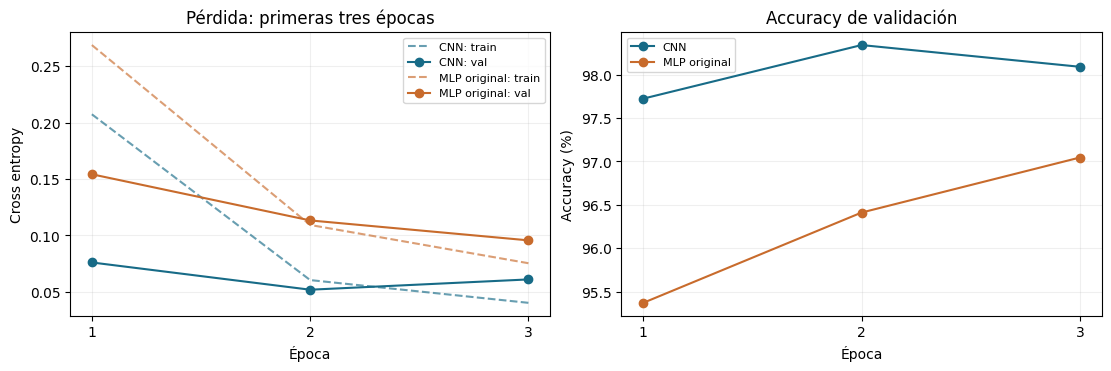

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
historial_mlp_3 = historial_mlp[historial_mlp["epoch"] <= EPOCHS_CNN]
for nombre, historial, color in [
    ("CNN", historial_cnn, "#176B87"),
    ("MLP original", historial_mlp_3, "#C86B2C"),
]:
    axes[0].plot(historial["epoch"], historial["train_loss"], "--", color=color,
                 alpha=0.65, label=f"{nombre}: train")
    axes[0].plot(historial["epoch"], historial["val_loss"], "o-", color=color,
                 label=f"{nombre}: val")
    axes[1].plot(historial["epoch"], 100 * historial["val_acc"], "o-", color=color, label=nombre)
axes[0].set(title="Pérdida: primeras tres épocas", ylabel="Cross entropy")
axes[1].set(title="Accuracy de validación", ylabel="Accuracy (%)")
for ax in axes:
    ax.set_xlabel("Época")
    ax.set_xticks(range(1, EPOCHS_CNN + 1))
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
plt.show()

### 2.12. Comparación con el resultado obtenido en el adjunto

`ExampleofNeuralNetworks.ipynb` guarda **Test Loss = 0.0890** y **Test Accuracy = 0.9761**, es decir, **97.61 %**, tras cinco épocas. Esta es la referencia histórica solicitada en el PDF.

Se muestra junto con la CNN nueva y el MLP reentrenado a cinco épocas. Comparar la CNN de tres épocas con el histórico es **descriptivo**: difieren las épocas y no se conservan los índices de aquella partición. La comparación a tres épocas de la sección anterior controla esas diferencias dentro de esta nueva ejecución.

In [13]:
resultado_historico = {
    "Modelo": "MLP del adjunto (histórico)",
    "Épocas": 5,
    "Parámetros": 235146,
    "Test loss": 0.089,
    "Test accuracy (%)": 97.61,
    "Tiempo train+val (s)": None,
}
comparacion_historica = mostrar_resultados([
    resultado_cnn,
    {**resultado_mlp_5, "Modelo": "MLP original (reentrenado)"},
    resultado_historico,
])
delta_historico = resultado_cnn["Test accuracy (%)"] - resultado_historico["Test accuracy (%)"]
print(f"Diferencia CNN nueva - MLP histórico: {delta_historico:+.2f} puntos porcentuales.")
print("La comparación histórica no aísla el efecto de la arquitectura: cambian épocas e índices del split.")

Diferencia CNN nueva - MLP histórico: +0.29 puntos porcentuales.
La comparación histórica no aísla el efecto de la arquitectura: cambian épocas e índices del split.


,Modelo,Épocas,Parámetros,Test loss,Test accuracy (%),Tiempo train+val (s)
0,CNN,3,"206,922",0.0606,97.90,30.6
1,MLP original (reentrenado),5,"235,146",0.1055,97.12,28.1
2,MLP del adjunto (histórico),5,"235,146",0.0890,97.61,-


## 3. Opcional: CNN con BatchNorm

Se agrega `BatchNorm2d` después de cada convolución y antes de ReLU, manteniendo las demás capas y sus sesgos. Sus escalas y desplazamientos suman $2\cdot16+2\cdot32=96$ parámetros entrenables; las medias y varianzas móviles son buffers.

**Total: 207 018 parámetros.** Se comparan las primeras tres épocas con igual partición, orden de lotes e inicialización de las capas compartidas. BatchNorm puede cambiar la convergencia, pero no garantiza un mejor resultado en tres épocas.

In [14]:
class SimpleCNNBN(SimpleCNN):
    def __init__(self):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(16)
        self.bn2 = nn.BatchNorm2d(32)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)

if EJECUTAR_BATCHNORM:
    fijar_semilla()
    base_inicial = SimpleCNN()
    fijar_semilla()
    bn_inicial = SimpleCNNBN()
    for nombre, tensor in base_inicial.state_dict().items():
        torch.testing.assert_close(tensor, bn_inicial.state_dict()[nombre])
    assert contar_parametros(bn_inicial) == 207018
    del base_inicial, bn_inicial
    cnn_bn, historial_bn, resultados_bn = ejecutar_experimento(
        SimpleCNNBN, "CNN + BatchNorm", epocas=EPOCHS_CNN
    )
    resultado_bn = resultados_bn[EPOCHS_CNN]
    mostrar_resultados([resultado_cnn, resultado_bn])
else:
    print("Ejercicio opcional omitido. Activa EJECUTAR_BATCHNORM para ejecutarlo.")

CNN + BatchNorm | época 1/3 | train loss=0.1627, acc=95.12% | val loss=0.0865, acc=97.34% | 13.1 s
CNN + BatchNorm | época 2/3 | train loss=0.0569, acc=98.26% | val loss=0.0574, acc=98.12% | 12.7 s
CNN + BatchNorm | época 3/3 | train loss=0.0420, acc=98.67% | val loss=0.0760, acc=97.69% | 13.0 s
CNN + BatchNorm | estado época 3 | Test accuracy: 97.94%


,Modelo,Épocas,Parámetros,Test loss,Test accuracy (%),Tiempo train+val (s)
0,CNN,3,"206,922",0.0606,97.90,30.6
1,CNN + BatchNorm,3,"207,018",0.0682,97.94,38.9


,Época,CNN val loss,BN val loss,CNN val accuracy (%),BN val accuracy (%)
0,1,0.0760,0.0865,97.7222,97.3444
1,2,0.0519,0.0574,98.3389,98.1222
2,3,0.0610,0.0760,98.0889,97.6889


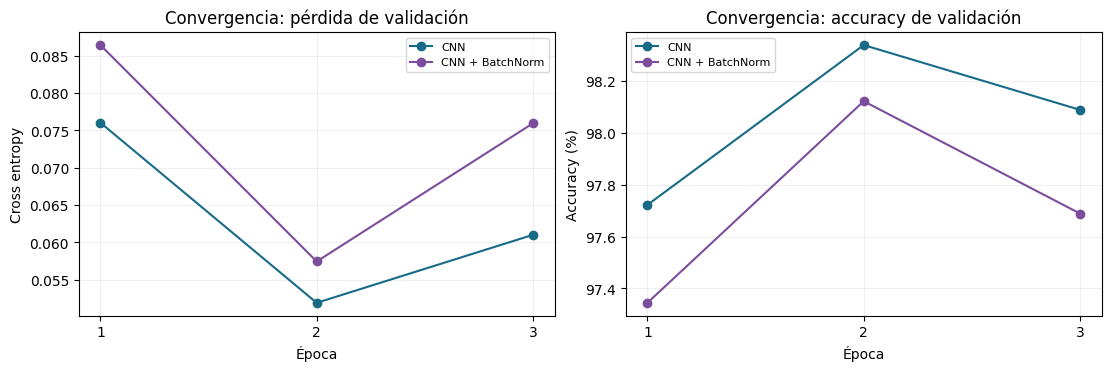

**Observación de esta ejecución:** BatchNorm cambia el accuracy de validación en -0.38 puntos porcentuales en la primera época y en -0.40 en la tercera. Su tiempo de entrenamiento y validación es 1.27 veces el de la CNN base. Las curvas muestran si la mejora es sostenida; una ejecución no establece una ventaja general.

In [15]:
if EJECUTAR_BATCHNORM:
    display(pd.DataFrame({
        "Época": historial_cnn["epoch"],
        "CNN val loss": historial_cnn["val_loss"],
        "BN val loss": historial_bn["val_loss"],
        "CNN val accuracy (%)": 100 * historial_cnn["val_acc"],
        "BN val accuracy (%)": 100 * historial_bn["val_acc"],
    }).round(4))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
    for nombre, historial, color in [
        ("CNN", historial_cnn, "#176B87"),
        ("CNN + BatchNorm", historial_bn, "#7C4D9D"),
    ]:
        axes[0].plot(historial["epoch"], historial["val_loss"], "o-", color=color, label=nombre)
        axes[1].plot(historial["epoch"], 100 * historial["val_acc"], "o-", color=color, label=nombre)
    axes[0].set(title="Convergencia: pérdida de validación", ylabel="Cross entropy")
    axes[1].set(title="Convergencia: accuracy de validación", ylabel="Accuracy (%)")
    for ax in axes:
        ax.set_xlabel("Época")
        ax.set_xticks(range(1, EPOCHS_CNN + 1))
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
    plt.show()

    delta_1 = 100 * (historial_bn.iloc[0]["val_acc"] - historial_cnn.iloc[0]["val_acc"])
    delta_3 = 100 * (historial_bn.iloc[-1]["val_acc"] - historial_cnn.iloc[-1]["val_acc"])
    razon_tiempo = resultado_bn["Tiempo train+val (s)"] / resultado_cnn["Tiempo train+val (s)"]
    display(Markdown(
        f"**Observación de esta ejecución:** BatchNorm cambia el accuracy de validación "
        f"en {delta_1:+.2f} puntos porcentuales en la primera época y "
        f"en {delta_3:+.2f} en la tercera. Su tiempo de entrenamiento y validación es "
        f"{razon_tiempo:.2f} veces el de la CNN base. "
        "Las curvas muestran si la mejora es sostenida; una ejecución no establece una ventaja general."
    ))

## 4. Pregunta de cierre: respuesta en tres líneas

Una CNN reutiliza los mismos filtros en todas las posiciones de la imagen: esa **compartición de pesos** evita aprender conexiones distintas para cada ubicación.  
Además, aprovecha patrones locales y reduce las dimensiones con pooling, lo que suele permitir buen accuracy con menos parámetros que un MLP comparable.  
La cantidad total depende de la arquitectura elegida; una CNN no siempre tiene menos parámetros que cualquier MLP.

## 5. Respuestas finales para el informe

La tabla incluye métricas nuevas e identifica expresamente el resultado histórico del adjunto. La diferencia de parámetros se calcula a partir de las arquitecturas originales.

In [16]:
filas = [
    {**resultado_cnn, "Origen": "Esta ejecución"},
    {**resultado_mlp_3, "Origen": "Esta ejecución"},
    {**resultado_mlp_5, "Origen": "Esta ejecución"},
    {**resultado_historico, "Origen": "Salida guardada en adjunto"},
]
if EJECUTAR_BATCHNORM:
    filas.append({**resultado_bn, "Origen": "Esta ejecución"})
resultados_finales = mostrar_resultados(filas)

display(Markdown(
    f"**Parte 1:** $f={f_manual:.12f}$; forward y los cinco gradientes coinciden con autograd.\n\n"
    "**Dimensiones:** 28 → 14 → 7; Conv2 recibe 16 canales y produce 32; "
    "FC1 recibe $32\\times7\\times7=1568$ entradas.\n\n"
    "**Parámetros:** CNN = 206 922; MLP original = 235 146. El MLP tiene 28 224 más.\n\n"
    f"**Test accuracy:** CNN, 3 épocas = {resultado_cnn['Test accuracy (%)']:.2f} %; "
    f"MLP, 3 épocas = {resultado_mlp_3['Test accuracy (%)']:.2f} %; "
    f"MLP, 5 épocas reentrenado = {resultado_mlp_5['Test accuracy (%)']:.2f} %.\n\n"
    "**Referencia histórica:** el adjunto reporta 97.61 % para el MLP tras 5 épocas. "
    "Su semilla e índices del split no quedaron guardados."
))

,Modelo,Épocas,Parámetros,Test loss,Test accuracy (%),Tiempo train+val (s),Origen
0,CNN,3,"206,922",0.0606,97.90,30.6,Esta ejecución
1,MLP original,3,"235,146",0.0913,97.15,16.6,Esta ejecución
2,MLP original,5,"235,146",0.1055,97.12,28.1,Esta ejecución
3,MLP del adjunto (histórico),5,"235,146",0.0890,97.61,-,Salida guardada en adjunto
4,CNN + BatchNorm,3,"207,018",0.0682,97.94,38.9,Esta ejecución


**Parte 1:** $f=0.268941421370$; forward y los cinco gradientes coinciden con autograd.

**Dimensiones:** 28 → 14 → 7; Conv2 recibe 16 canales y produce 32; FC1 recibe $32\times7\times7=1568$ entradas.

**Parámetros:** CNN = 206 922; MLP original = 235 146. El MLP tiene 28 224 más.

**Test accuracy:** CNN, 3 épocas = 97.90 %; MLP, 3 épocas = 97.15 %; MLP, 5 épocas reentrenado = 97.12 %.

**Referencia histórica:** el adjunto reporta 97.61 % para el MLP tras 5 épocas. Su semilla e índices del split no quedaron guardados.

## Referencias utilizadas

- `Practica_2_Backprop_CNN.pdf`: circuito manual, arquitectura CNN, tres épocas y preguntas de la práctica.
- `ExampleofNeuralNetworks.ipynb`: MLP original, split 70/30, transformaciones, hiperparámetros, funciones de entrenamiento/evaluación y salida histórica de 97.61 %.
- `NeuralNetwork_MNIST.ipynb`: confirma el MLP y las transformaciones; utiliza 60 000 ejemplos de entrenamiento sin validación.
- [PyTorch: Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html).
- [PyTorch: CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).
- [Torchvision: MNIST](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html).